<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/50_vinculos/52_panel_exploracion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 52 · Panel municipio × año: construcción y descriptivos

**Autor:** Jonatan

**Pregunta:** ¿cómo se arma el panel municipal 2001–2024 (168 filas) con cobertura, quema, focos, lluvia y ONI, y qué muestran sus descriptivos?

**Entradas:**
- `datos/comunes/`: `firms_mensual_municipio.csv` (cuaderno 03), `chirps_mensual_municipio.csv` (cuaderno 11) y `oni_mensual.csv` (cuaderno 10).
- `modulos/expansion/datos/procesados/` (DVC): coberturas MapBiomas y EVA, de los scripts `02_unir_mapbiomas.py` y `03_series_y_cruce_eva.py` del módulo de expansión.
- `modulos/fuego_expansion/datos/crudos/` (DVC): área quemada de MapBiomas Fuego y pérdida de vegetación.
- El panel municipio × año se construye en el cuaderno con `scripts/01_preparar_panel.py`, así que no depende de otro cuaderno.

**Salidas:**
- `modulos/fuego_expansion/datos/derivados/municipal/`: `panel_municipio_anio.csv` y `serie_altillanura_anual.csv` (no se versionan).
- `modulos/fuego_expansion/resultados/tablas/municipal/descriptivo_por_municipio.csv`.
- `modulos/fuego_expansion/resultados/figuras/municipal/01_series_regionales.png`.

**Método:** unión por código DIVIPOLA y año, indicadores de cambio agropecuario en dos escalas y serie regional con denominadores regionales. FIRMS: Terra + Aqua desde 2003 y Terra sola como sensibilidad.

## Datos y objetivo del análisis municipal

Evaluamos si, entre 2001 y 2024, los años con mayor proporción quemada de vegetación natural no forestal se asocian con un mayor cambio neto agropecuario ese año o al siguiente dentro de los siete municipios de la Altillanura. La unidad de análisis es el **municipio-año**.

Una **cobertura** es una clase asignada por MapBiomas a un píxel en el mapa de un año. Al sumar los píxeles de cada clase se obtienen las superficies municipales. La **formación natural no forestal** agrupa praderas, humedales y otras formaciones naturales no forestales. La categoría **agropecuaria** incluye mosaico de agricultura y pastos, palma de aceite y plantaciones forestales. El cuaderno 50 evalúa la sensibilidad del indicador principal al excluir plantaciones.

Sea $A_t$ el área agropecuaria y $T_t$ el área total del municipio en el año $t$. Ambos indicadores parten del mismo **cambio neto en hectáreas**, $A_t-A_{t-1}$. Ese saldo recoge todas las entradas y salidas de la categoría agropecuaria. Un valor negativo indica una pérdida neta.

- **Principal (`d_agro_pct`).** $100(A_t-A_{t-1})/T_{t-1}$, en puntos porcentuales (pp) del territorio del año anterior.
- **Complementario (`crec_agro_pct`).** $100(A_t-A_{t-1})/A_{t-1}$, en porcentaje de crecimiento respecto a la superficie agropecuaria del año anterior.

Si un municipio de 100.000 ha pasa de 20.000 a 21.000 ha agropecuarias, el saldo es +1.000 ha, equivalente a **+1 pp del territorio** y a **+5 % de la base agropecuaria**. Una misma ganancia puede representar un porcentaje grande si la base agropecuaria es pequeña. Si el denominador falta o es cero, el indicador correspondiente queda sin valor. El área total de cada municipio es prácticamente constante en esta fuente.

La **tasa de quema natural** es 100 veces las hectáreas quemadas de formación natural no forestal divididas por las hectáreas de esa misma cobertura en el mismo año calendario. Se usan hectáreas como supuesto de trabajo porque el CSV de fuego carece de un campo de unidad.

## 1. Preparar el entorno

Esta celda ubica la raíz del proyecto, carga las funciones de `scripts/` y define dónde guardar los datos derivados, las tablas y las figuras del análisis municipal.

In [1]:
import sys
from importlib import import_module
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Rutas del proyecto: funcionan en Colab y en local
import os, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/

def traer(ruta):
    """Baja de DVC una carpeta o un archivo pesado del repo si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

traer('modulos/fuego_expansion/datos/crudos')
traer('modulos/expansion/datos/procesados')
sys.path.insert(0, os.path.join(RAIZ, 'modulos', 'fuego_expansion', 'scripts'))

import config as cfg
from utils import estilo_matplotlib, leer_csv

derivados = cfg.DERIVADOS / "municipal"
tablas = cfg.TABLAS / "municipal"
figuras = cfg.FIGURAS / "municipal"
for carpeta in (derivados, tablas, figuras):
    carpeta.mkdir(parents=True, exist_ok=True)
estilo_matplotlib()

## 2. Construir el panel y la serie regional

Se combinan las fuentes por código DANE y año. La validación exige **168 filas únicas**, una por cada combinación de siete municipios y 24 años. El año 2000 sirve de insumo para calcular el cambio agropecuario y el rezago de quema de 2001.

La serie regional se obtiene agregando superficies y recalculando las proporciones a partir de los totales. Por ejemplo, la tasa regional divide todas las hectáreas naturales no forestales quemadas entre todas las hectáreas de esa cobertura. Los municipios aportan según el tamaño de la cobertura, a diferencia de un promedio simple de tasas municipales.

Para ambos indicadores agropecuarios, el agregado regional suma primero los cambios netos en hectáreas de los siete municipios. Después divide por la suma regional del denominador de $t-1$. El panel y la serie conservan ambos denominadores en `area_total_ha_rez1` y `agro_ha_rez1`.

In [2]:
preparar = import_module("01_preparar_panel")
explorar = import_module("02_exploracion")

panel = preparar.construir_panel()
regional = preparar.serie_regional(panel)
esperado = len(cfg.MUNICIPIOS) * (cfg.ANIO_FIN - cfg.ANIO_INI + 1)
assert len(panel) == esperado and not panel.duplicated(["cod_mun", "anio"]).any()
preparar.para_exportar(panel).to_csv(derivados / "panel_municipio_anio.csv", index=False)
regional.to_csv(derivados / "serie_altillanura_anual.csv", index=False)

resumen = explorar.descriptivo(panel)
resumen.to_csv(tablas / "descriptivo_por_municipio.csv", encoding="utf-8-sig")
display(resumen)

,mpio_cdpmp,area_total_ha,agro_2001_ha,agro_2024_ha,expansion_media_ha_anio,cambio_medio_pp_territorio,crecimiento_medio_pct_agro_previo,focos_seca_medios,focos_seca_por_100km2,focos_seca_terra_medios,quemado_medio_ha_anio,quemado_medio_pct_municipio,quemado_agro_medio_ha_anio,quemado_sabana_medio_ha_anio,lluvia_seca_media_mm,expansion_total_ha
municipio,,,,,,,,,,,,,,,,
Cumaribo,99773,6503149.78,133735.88,232866.25,4412.77,0.07,2.59,2253.95,3.47,1040.42,479734.57,7.38,7254.12,467585.11,369.78,99130.37
La Primavera,99524,1831799.06,32471.79,218830.79,7830.13,0.43,8.87,1203.77,6.57,686.75,380941.36,20.80,4575.24,374367.00,194.67,186359.00
Puerto Gaitán,50568,1721864.68,301427.35,495551.15,7895.25,0.46,2.06,1618.23,9.40,875.88,321939.45,18.70,28652.70,288106.92,274.76,194123.80
Mapiripán,50325,1193129.14,118423.71,241215.18,5228.03,0.44,3.18,743.14,6.23,308.71,92933.47,7.79,8383.43,83570.47,398.42,122791.48
Puerto Carreño,99001,1178791.89,29228.96,142366.70,4500.76,0.38,6.78,689.68,5.85,389.21,258281.96,21.91,8455.06,248597.76,133.62,113137.74
Puerto López,50573,690884.09,270133.96,332837.81,2741.31,0.40,0.94,254.95,3.69,142.46,43444.21,6.29,6124.17,36940.78,313.37,62703.85
Santa Rosalía,99624,367755.92,21372.80,71546.53,2058.37,0.56,5.23,290.23,7.89,154.88,71544.57,19.45,4964.82,66170.91,225.68,50173.72


### Lectura del resumen municipal

Entre 2001 y 2024 el área agropecuaria aumenta en los siete municipios. **Puerto Gaitán** registra el mayor aumento neto en hectáreas, unas **194.124 ha**, seguido de **La Primavera**, con **186.359 ha**. La columna de aumento total compara directamente 2024 con 2001. Las tres medias anuales (ha, pp del territorio y % del agro previo) usan los cambios disponibles para 2001–2024 e incluyen el cambio de 2000 a 2001.

Cumaribo registra más focos secos en promedio que cualquier otro municipio, cerca de **2.254 por temporada** (Terra + Aqua, 2003–2024; **1.040** con Terra sola), mientras que Puerto Gaitán tiene la mayor densidad, **9,40 focos por 100 km²**. El recuento total y la densidad responden preguntas distintas cuando los municipios tienen áreas muy diferentes. En esta tabla, el nombre histórico de columna `quemado_sabana_medio_ha_anio` se refiere a toda la formación natural no forestal quemada.

## 3. Cobertura temporal y calidad

La tabla siguiente cuenta los datos disponibles para las variables del modelo. CHIRPS aporta la lluvia de diciembre del año anterior a marzo del año analizado. FIRMS (Terra + Aqua desde 2003, con Terra sola como sensibilidad) aporta detecciones térmicas de esa misma temporada como contraste de la superficie quemada anual.

MapBiomas incorporó MODIS MCD64A1 como apoyo complementario a Landsat en **2002, 2005 y 2007**. El panel conserva los tres años y marca cuándo entran como medición del año actual o como rezago. El cuaderno 50 usa esas marcas para evaluar cuánto cambia el resultado al excluirlos. [Nota de calidad de MapBiomas Fuego](https://colombia.mapbiomas.org/iniciativas-y-productos/fuego/calidad-mosaico/)

In [3]:
variables = ["d_agro_pct", "crec_agro_pct", "tasa_quema_natural", "tasa_quema_natural_rez1",
             "lluvia_seca_mm", "focos_seca_dens", "focos_seca_dens_rez1"]
display(panel.groupby("municipio")[variables].count())
display(panel.loc[panel["fuego_calidad_limitada"], "anio"].unique())

,d_agro_pct,crec_agro_pct,tasa_quema_natural,tasa_quema_natural_rez1,lluvia_seca_mm,focos_seca_dens,focos_seca_dens_rez1
municipio,,,,,,,
Cumaribo,24,24,24,24,24,22,21
La Primavera,24,24,24,24,24,22,21
Mapiripán,24,24,24,24,24,22,21
Puerto Carreño,24,24,24,24,24,22,21
Puerto Gaitán,24,24,24,24,24,22,21
Puerto López,24,24,24,24,24,22,21
Santa Rosalía,24,24,24,24,24,22,21


array([2002, 2005, 2007])

La quema contemporánea, la quema rezagada, ambas medidas de cambio agropecuario y la lluvia tienen **168 datos disponibles cada uno**. Los focos de la temporada seca tienen **154** porque la serie Terra + Aqua comienza en 2003, y su rezago tiene **147** porque empieza en 2004. Por eso la comparación entre MapBiomas y FIRMS del cuaderno 50 usa una muestra común de 2004–2024.

## 4. Visualizar las series regionales

Los dos paneles superiores muestran el mismo saldo agropecuario en las dos escalas. El panel inferior muestra qué porcentaje de la formación natural no forestal se quemó en cada año. Las bandas grises marcan los años con limitaciones de Landsat.

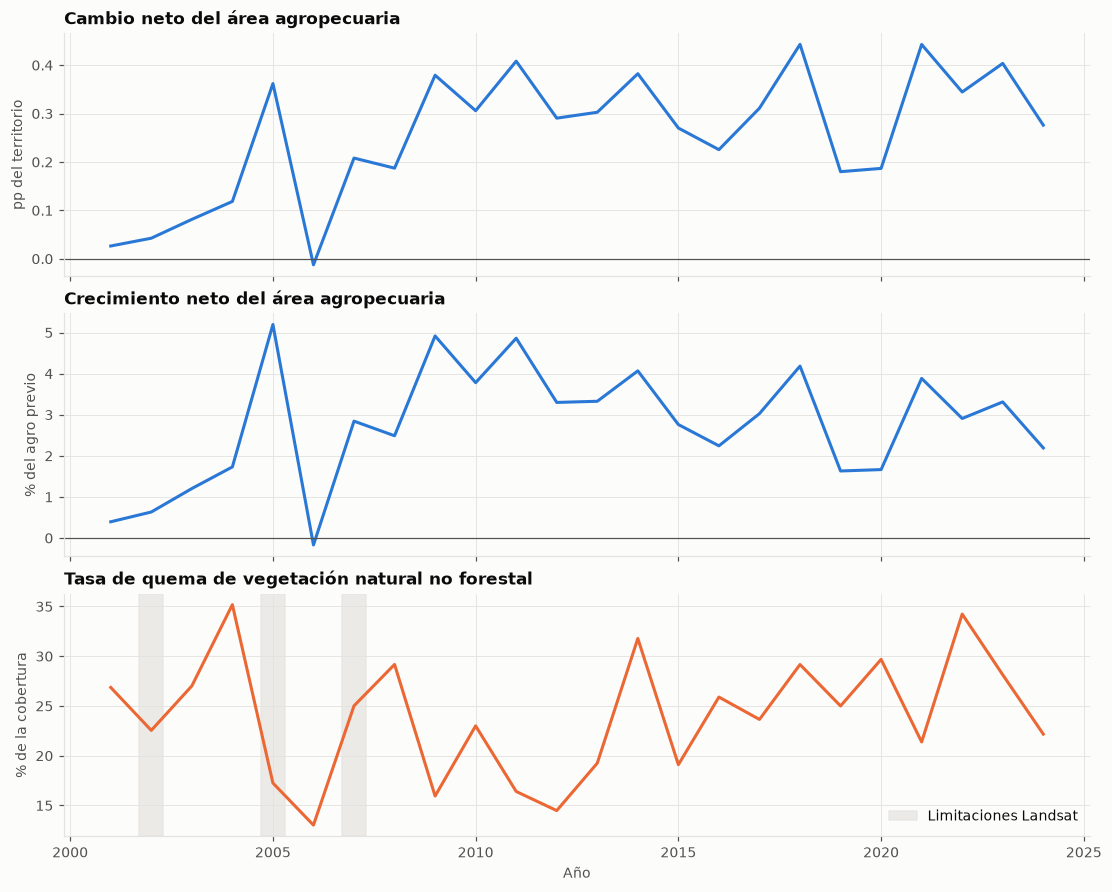

In [4]:
fig, ejes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout="constrained")
ejes[0].plot(regional["anio"], regional["d_agro_pct"], color=cfg.COLOR_AGRO)
ejes[0].axhline(0, color=cfg.COLOR_TEXTO_2, linewidth=0.8)
ejes[0].set(title="Cambio neto del área agropecuaria", ylabel="pp del territorio")
ejes[1].plot(regional["anio"], regional["crec_agro_pct"], color=cfg.COLOR_AGRO)
ejes[1].axhline(0, color=cfg.COLOR_TEXTO_2, linewidth=0.8)
ejes[1].set(title="Crecimiento neto del área agropecuaria", ylabel="% del agro previo")
ejes[2].plot(regional["anio"], regional["tasa_quema_natural"], color=cfg.COLOR_SABANA)
ejes[2].set(title="Tasa de quema de vegetación natural no forestal", ylabel="% de la cobertura",
            xlabel="Año")
for i, anio in enumerate(cfg.ANIOS_FUEGO_LIMITADOS):
    ejes[2].axvspan(anio - 0.3, anio + 0.3, color=cfg.COLOR_GRILLA, alpha=0.7,
                    label="Limitaciones Landsat" if i == 0 else None)
ejes[2].legend()
fig.savefig(figuras / "01_series_regionales.png")
plt.show()

### Lectura de la figura

El área agropecuaria registra aumentos netos en 23 de los 24 años. El menor cambio es **−0,01 pp en 2006** y el mayor es **+0,44 pp en 2018**. La tasa de quema es más variable y oscila entre **13,0 % en 2006** y **35,2 % en 2004**. La coincidencia de dos valores bajos en 2006 describe ese año. La asociación a lo largo de todo el período se evalúa en el cuaderno 50.

Las dos escalas tienen el mismo signo en cada año. La escala relativa al agro previo da más peso a la misma ganancia en hectáreas cuando el área agropecuaria de partida es menor.